In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris, load_wine, load_breast_cancer, fetch_lfw_people, fetch_olivetti_faces
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
from google.colab import files

print("env setup")

env setup


In [2]:
iris = load_iris()
wine = load_wine()
cancer = load_breast_cancer()
lfw = fetch_lfw_people(min_faces_per_person=70, resize=0.4)
olivetti = fetch_olivetti_faces()

raw_datasets = {
    'Iris': (iris.data, iris.target, 'Botany / Morphological'),
    'Wine': (wine.data, wine.target, 'Analytical Chemistry'),
    'Breast Cancer': (cancer.data, cancer.target, 'Oncology / Histopathology'),
    'LFW People': (lfw.data, lfw.target, 'Biometrics / Computer Vision'),
    'Olivetti Faces': (olivetti.data, olivetti.target, 'Biometrics / Computer Vision')
}

dataset_metadata = []
for name, (X, y, domain) in raw_datasets.items():
    dataset_metadata.append({
        'Dataset': name,
        'Samples ($N$)': X.shape[0],
        'Features ($D$)': X.shape[1],
        'Classes ($C$)': len(np.unique(y)),
        'Domain Space': domain
    })

print("\n" + "="*80 + "\nTABLE I: COMPREHENSIVE EXPERIMENTAL DATASET CHARACTERISTICS\n" + "="*80)
print(pd.DataFrame(dataset_metadata).to_markdown(index=False))

lfw_class_counts = pd.Series(lfw.target).value_counts().sort_index()
lfw_class_table = pd.DataFrame({
    'Subject': [lfw.target_names[i] for i in lfw_class_counts.index],
    'Count': lfw_class_counts.values,
    'Share of N (%)': (lfw_class_counts.values / lfw_class_counts.sum() * 100).round(2)
}).sort_values('Count', ascending=False).reset_index(drop=True)

print("\n" + "="*80 + "\nLFW PEOPLE: PER-CLASS SAMPLE DISTRIBUTION (min_faces_per_person=70)\n" + "="*80)
print(lfw_class_table.to_markdown(index=False))

olivetti_class_counts = pd.Series(olivetti.target).value_counts().sort_index()
print("\n" + "="*80 + "\nOLIVETTI FACES: PER-CLASS SAMPLE DISTRIBUTION (balanced, 10 per class)\n" + "="*80)
print(f"Total samples: {len(olivetti.target)}, Classes: {len(np.unique(olivetti.target))}, Samples per class: {olivetti_class_counts.iloc[0]}")

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data

TABLE I: COMPREHENSIVE EXPERIMENTAL DATASET CHARACTERISTICS
| Dataset        |   Samples ($N$) |   Features ($D$) |   Classes ($C$) | Domain Space                 |
|:---------------|----------------:|-----------------:|----------------:|:-----------------------------|
| Iris           |             150 |                4 |               3 | Botany / Morphological       |
| Wine           |             178 |               13 |               3 | Analytical Chemistry         |
| Breast Cancer  |             569 |               30 |               2 | Oncology / Histopathology    |
| LFW People     |            1288 |             1850 |               7 | Biometrics / Computer Vision |
| Olivetti Faces |             400 |             4096 |              40 | Biometrics / Computer Vision |

LFW PEOPLE: PER-CLASS SAMPLE DISTRIBUTION (min_faces_per_person=70)
| Subject           |   Count

In [3]:
metrics = ['euclidean', 'manhattan', 'chebyshev', 'cosine']
variants = ['uniform', 'distance']
seeds = list(range(10))
baseline_K = 5

master_run_log = []

for name, (X, y, _) in raw_datasets.items():

    for metric in metrics:
        for variant in variants:
            acc_accumulator = []
            f1_accumulator = []
            kappa_accumulator = []

            for seed in seeds:
                X_train_raw, X_test_raw, y_train, y_test = train_test_split(
                    X, y, test_size=0.2, random_state=seed, stratify=y
                )
                scaler = MinMaxScaler()
                X_train = scaler.fit_transform(X_train_raw)
                X_test = scaler.transform(X_test_raw)

                knn = KNeighborsClassifier(n_neighbors=baseline_K, metric=metric, weights=variant)
                knn.fit(X_train, y_train)

                y_pred = knn.predict(X_test)
                acc_accumulator.append(accuracy_score(y_test, y_pred) * 100.0)
                f1_accumulator.append(f1_score(y_test, y_pred, average='macro') * 100.0)
                kappa_accumulator.append(cohen_kappa_score(y_test, y_pred))

            master_run_log.append({
                'Dataset': name,
                'Metric': metric,
                'Weights': variant,
                'Mean Accuracy (%)': np.mean(acc_accumulator),
                'Std Accuracy (%)': np.std(acc_accumulator),
                'Mean F1 Macro (%)': np.mean(f1_accumulator),
                'Std F1 Macro (%)': np.std(f1_accumulator),
                'Mean Cohen Kappa': np.mean(kappa_accumulator),
            })

df_master = pd.DataFrame(master_run_log)
print("Core matrix computation (accuracy / F1 / kappa)")

Core matrix computation (accuracy / F1 / kappa)


In [4]:
print("\n" + "="*90 + "\nTABLE II: MULTI-SEED STATISTICAL PERFORMANCE FOOTPRINTS (UNIFORM WEIGHTS)\n" + "="*90)
df_uniform = df_master[df_master['Weights'] == 'uniform'].copy()
df_uniform_display = df_uniform.map(lambda x: f"{x:.2f}" if isinstance(x, (float, np.float64)) else x)
print(df_uniform_display[['Dataset', 'Metric', 'Mean Accuracy (%)', 'Std Accuracy (%)', 'Mean F1 Macro (%)', 'Mean Cohen Kappa']].to_markdown(index=False))

print("\n" + "="*90 + "\nTABLE III: MULTI-SEED STATISTICAL PERFORMANCE FOOTPRINTS (DISTANCE-WEIGHTED VARIANT)\n" + "="*90)
df_distance = df_master[df_master['Weights'] == 'distance'].copy()
df_distance_display = df_distance.map(lambda x: f"{x:.2f}" if isinstance(x, (float, np.float64)) else x)
print(df_distance_display[['Dataset', 'Metric', 'Mean Accuracy (%)', 'Std Accuracy (%)', 'Mean F1 Macro (%)', 'Mean Cohen Kappa']].to_markdown(index=False))

# LFW majority-class baseline
lfw_X, lfw_y, _ = raw_datasets['LFW People']
majority_baseline_accs = []
for seed in seeds:
    _, _, y_train, y_test = train_test_split(
        lfw_X, lfw_y, test_size=0.2, random_state=seed, stratify=lfw_y
    )
    majority_class = pd.Series(y_train).mode()[0]
    majority_baseline_accs.append((y_test == majority_class).mean() * 100.0)

print("\n" + "="*80 + "\nLFW PEOPLE: MAJORITY-CLASS BASELINE (10-SEED MEAN, SAME TEST SPLITS AS TABLE II)\n" + "="*80)
print(f"Mean: {np.mean(majority_baseline_accs):.2f}%   SD: {np.std(majority_baseline_accs):.2f} pp")
print("(Note: with a stratified split this will have very low seed-to-seed SD by")
print("construction -- that is expected, not an error.)")


TABLE II: MULTI-SEED STATISTICAL PERFORMANCE FOOTPRINTS (UNIFORM WEIGHTS)
| Dataset        | Metric    |   Mean Accuracy (%) |   Std Accuracy (%) |   Mean F1 Macro (%) |   Mean Cohen Kappa |
|:---------------|:----------|--------------------:|-------------------:|--------------------:|-------------------:|
| Iris           | euclidean |               96    |               2.91 |               95.99 |               0.94 |
| Iris           | manhattan |               95    |               3.73 |               94.99 |               0.93 |
| Iris           | chebyshev |               94.33 |               4.48 |               94.32 |               0.91 |
| Iris           | cosine    |               81.67 |               6.19 |               81.15 |               0.72 |
| Wine           | euclidean |               96.39 |               1.78 |               96.43 |               0.95 |
| Wine           | manhattan |               97.22 |               2.15 |               97.27 |           

In [5]:
from sklearn.preprocessing import StandardScaler
from scipy.stats import spearmanr

preprocessing_conditions = ['Raw', 'Z-Score', 'Min-Max']

preprocessing_run_log = []

for name, (X, y, _) in raw_datasets.items():
    for metric in metrics:
        for variant in variants:
            for prep in preprocessing_conditions:
                acc_accumulator = []
                f1_accumulator = []
                kappa_accumulator = []

                for seed in seeds:
                    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
                        X, y, test_size=0.2, random_state=seed, stratify=y
                    )

                    if prep == 'Raw':
                        X_train, X_test = X_train_raw, X_test_raw
                    elif prep == 'Z-Score':
                        scaler = StandardScaler()
                        X_train = scaler.fit_transform(X_train_raw)
                        X_test = scaler.transform(X_test_raw)
                    else:
                        scaler = MinMaxScaler()
                        X_train = scaler.fit_transform(X_train_raw)
                        X_test = scaler.transform(X_test_raw)

                    knn = KNeighborsClassifier(n_neighbors=baseline_K, metric=metric, weights=variant)
                    knn.fit(X_train, y_train)
                    y_pred = knn.predict(X_test)

                    acc_accumulator.append(accuracy_score(y_test, y_pred) * 100.0)
                    f1_accumulator.append(f1_score(y_test, y_pred, average='macro') * 100.0)
                    kappa_accumulator.append(cohen_kappa_score(y_test, y_pred))

                preprocessing_run_log.append({
                    'Dataset': name,
                    'Metric': metric,
                    'Weights': variant,
                    'Preprocessing': prep,
                    'Mean Accuracy (%)': np.mean(acc_accumulator),
                    'Std Accuracy (%)': np.std(acc_accumulator),
                    'Mean F1 Macro (%)': np.mean(f1_accumulator),
                    'Mean Cohen Kappa': np.mean(kappa_accumulator),
                })

df_preprocessing = pd.DataFrame(preprocessing_run_log)

print("\n" + "="*90 + "\nPREPROCESSING SENSITIVITY: MEAN ACCURACY (%) BY CONDITION, K=5\n" + "="*90)
for variant in variants:
    print(f"\n--- {variant.upper()} WEIGHTING ---")
    subset = df_preprocessing[df_preprocessing['Weights'] == variant]
    prep_pivot = subset.pivot_table(index=['Dataset', 'Metric'], columns='Preprocessing', values='Mean Accuracy (%)')
    prep_pivot = prep_pivot[preprocessing_conditions]
    print(prep_pivot.round(2).to_markdown())

print("\n" + "="*90 + "\nRANKING STABILITY: TOP-ACCURACY METRIC PER (DATASET, WEIGHTING), BY PREPROCESSING\n" + "="*90)
stability_rows = []
for (name, variant), grp in df_preprocessing.groupby(['Dataset', 'Weights']):
    winners = {}
    for prep in preprocessing_conditions:
        prep_grp = grp[grp['Preprocessing'] == prep].set_index('Metric')['Mean Accuracy (%)']
        winners[prep] = prep_grp.idxmax()
    stable = len(set(winners.values())) == 1
    stability_rows.append({
        'Dataset': name, 'Weights': variant,
        'Winner (Raw)': winners['Raw'], 'Winner (Z-Score)': winners['Z-Score'], 'Winner (Min-Max)': winners['Min-Max'],
        'Winner Stable Across All 3?': 'Yes' if stable else 'No',
    })

df_stability = pd.DataFrame(stability_rows)
print(df_stability.to_markdown(index=False))

n_unstable = (df_stability['Winner Stable Across All 3?'] == 'No').sum()
print(f"\n{n_unstable} of {len(df_stability)} (dataset, weighting) pairs change their top-ranked metric depending on preprocessing.")

print("\n" + "="*90 + "\nRANK CORRELATION BETWEEN PREPROCESSING CONDITIONS (SPEARMAN RHO OVER THE 4 METRICS)\n" + "="*90)
rho_rows = []
for (name, variant), grp in df_preprocessing.groupby(['Dataset', 'Weights']):
    acc_by_prep = {
        prep: grp[grp['Preprocessing'] == prep].set_index('Metric')['Mean Accuracy (%)'].reindex(metrics)
        for prep in preprocessing_conditions
    }
    rho_raw_minmax, _ = spearmanr(acc_by_prep['Raw'], acc_by_prep['Min-Max'])
    rho_zscore_minmax, _ = spearmanr(acc_by_prep['Z-Score'], acc_by_prep['Min-Max'])
    rho_raw_zscore, _ = spearmanr(acc_by_prep['Raw'], acc_by_prep['Z-Score'])
    rho_rows.append({
        'Dataset': name, 'Weights': variant,
        'rho(Raw, Min-Max)': rho_raw_minmax, 'rho(Z-Score, Min-Max)': rho_zscore_minmax, 'rho(Raw, Z-Score)': rho_raw_zscore,
    })
df_rho = pd.DataFrame(rho_rows)
print("(n=4 metrics per correlation, so treat as a coarse supplementary signal, not a precise estimate.)")
print(df_rho.round(3).to_markdown(index=False))

df_preprocessing.to_csv('preprocessing_sensitivity_results.csv', index=False)


PREPROCESSING SENSITIVITY: MEAN ACCURACY (%) BY CONDITION, K=5

--- UNIFORM WEIGHTING ---
|                                 |   Raw |   Z-Score |   Min-Max |
|:--------------------------------|------:|----------:|----------:|
| ('Breast Cancer', 'chebyshev')  | 93.42 |     95.79 |     95.35 |
| ('Breast Cancer', 'cosine')     | 92.63 |     96.93 |     92.98 |
| ('Breast Cancer', 'euclidean')  | 94.3  |     97.72 |     97.46 |
| ('Breast Cancer', 'manhattan')  | 94.74 |     97.28 |     97.28 |
| ('Iris', 'chebyshev')           | 97    |     94.67 |     94.33 |
| ('Iris', 'cosine')              | 98.33 |     85.67 |     81.67 |
| ('Iris', 'euclidean')           | 96.67 |     95    |     96    |
| ('Iris', 'manhattan')           | 96.33 |     95    |     95    |
| ('LFW People', 'chebyshev')     | 35.89 |     38.91 |     37.21 |
| ('LFW People', 'cosine')        | 61.71 |     60.35 |     62.67 |
| ('LFW People', 'euclidean')     | 56.24 |     60.58 |     58.84 |
| ('LFW People', 'manhatt

In [6]:
from sklearn.metrics import confusion_matrix

lfw_labels_sorted = sorted(np.unique(lfw_y).tolist())

perclass_f1_log = []
lfw_confusion_sums = {metric: np.zeros((len(lfw_labels_sorted), len(lfw_labels_sorted))) for metric in metrics}

for metric in metrics:
    for seed in seeds:
        X_train_raw, X_test_raw, y_train, y_test = train_test_split(
            lfw_X, lfw_y, test_size=0.2, random_state=seed, stratify=lfw_y
        )
        scaler = MinMaxScaler()
        X_train = scaler.fit_transform(X_train_raw)
        X_test = scaler.transform(X_test_raw)

        knn = KNeighborsClassifier(n_neighbors=baseline_K, metric=metric, weights='uniform')
        knn.fit(X_train, y_train)
        y_pred = knn.predict(X_test)

        per_class_f1 = f1_score(y_test, y_pred, average=None, labels=lfw_labels_sorted, zero_division=0) * 100.0
        for cls, f1_val in zip(lfw_labels_sorted, per_class_f1):
            perclass_f1_log.append({'Metric': metric, 'Seed': seed, 'Class': lfw.target_names[cls], 'F1 (%)': f1_val})

        lfw_confusion_sums[metric] += confusion_matrix(y_test, y_pred, labels=lfw_labels_sorted)

df_perclass_f1 = pd.DataFrame(perclass_f1_log)

print("\n" + "="*90 + "\nLFW PER-CLASS F1 (%), MEAN OVER TEN SEEDS, K=5 UNIFORM\n" + "="*90)
perclass_pivot = df_perclass_f1.pivot_table(index='Class', columns='Metric', values='F1 (%)', aggfunc='mean')
perclass_pivot = perclass_pivot[metrics]

perclass_pivot['Mean Test Support / Seed'] = (lfw_confusion_sums[metrics[0]].sum(axis=1) / len(seeds)).round(1)
print(perclass_pivot.round(2).to_markdown())

best_metric_lfw = df_uniform[df_uniform['Dataset'] == 'LFW People'].set_index('Metric')['Mean Accuracy (%)'].idxmax()
worst_metric_lfw = df_uniform[df_uniform['Dataset'] == 'LFW People'].set_index('Metric')['Mean Accuracy (%)'].idxmin()

print("\n" + "="*90 + f"\nAGGREGATE CONFUSION MATRIX, BEST METRIC ({best_metric_lfw.upper()}), SUMMED OVER 10 SEEDS\n" + "="*90)
cm_best = pd.DataFrame(lfw_confusion_sums[best_metric_lfw].astype(int),
                        index=[f"true: {n}" for n in lfw.target_names],
                        columns=[f"pred: {n}" for n in lfw.target_names])
print(cm_best.to_markdown())

print("\n" + "="*90 + f"\nAGGREGATE CONFUSION MATRIX, WORST METRIC ({worst_metric_lfw.upper()}), SUMMED OVER 10 SEEDS\n" + "="*90)
cm_worst = pd.DataFrame(lfw_confusion_sums[worst_metric_lfw].astype(int),
                         index=[f"true: {n}" for n in lfw.target_names],
                         columns=[f"pred: {n}" for n in lfw.target_names])
print(cm_worst.to_markdown())

df_perclass_f1.to_csv('lfw_perclass_f1_results.csv', index=False)


LFW PER-CLASS F1 (%), MEAN OVER TEN SEEDS, K=5 UNIFORM
| Class             |   euclidean |   manhattan |   chebyshev |   cosine |   Mean Test Support / Seed |
|:------------------|------------:|------------:|------------:|---------:|---------------------------:|
| Ariel Sharon      |       38.87 |       36.48 |       12.3  |    53.18 |                         16 |
| Colin Powell      |       61.18 |       63.25 |       33.15 |    63.99 |                         47 |
| Donald Rumsfeld   |       46    |       55.63 |        8.06 |    53.07 |                         24 |
| George W Bush     |       73.15 |       75.81 |       55.75 |    74.32 |                        106 |
| Gerhard Schroeder |       28.03 |       31.16 |        9.35 |    37.76 |                         22 |
| Hugo Chavez       |       26.41 |       27.28 |        6.98 |    21.7  |                         14 |
| Tony Blair        |       36.28 |       37.65 |        8.61 |    46.37 |                         29 |

AGGREGA

In [7]:
K_values = [1, 3, 5, 7, 9, 15]
k_sweep_log = []

for name, (X, y, _) in raw_datasets.items():
    for metric in metrics:
        for K in K_values:
            acc_accumulator = []
            for seed in seeds:
                X_train_raw, X_test_raw, y_train, y_test = train_test_split(
                    X, y, test_size=0.2, random_state=seed, stratify=y
                )
                scaler = MinMaxScaler()
                X_train = scaler.fit_transform(X_train_raw)
                X_test = scaler.transform(X_test_raw)

                knn = KNeighborsClassifier(n_neighbors=K, metric=metric, weights='uniform')
                knn.fit(X_train, y_train)
                y_pred = knn.predict(X_test)
                acc_accumulator.append(accuracy_score(y_test, y_pred) * 100.0)

            k_sweep_log.append({
                'Dataset': name, 'Metric': metric, 'K': K,
                'Mean Accuracy (%)': np.mean(acc_accumulator),
                'Std Accuracy (%)': np.std(acc_accumulator)
            })

df_k_sweep = pd.DataFrame(k_sweep_log)

print("\n" + "="*90 + "\nTABLE: K-SENSITIVITY SWEEP (MEAN ACCURACY %, UNIFORM WEIGHTING)\n" + "="*90)
k_pivot = df_k_sweep.pivot_table(index=['Dataset', 'Metric'], columns='K', values='Mean Accuracy (%)')
print(k_pivot.round(2).to_markdown())

print("\nBest K per (Dataset, Metric):")
best_k_rows = df_k_sweep.loc[df_k_sweep.groupby(['Dataset', 'Metric'])['Mean Accuracy (%)'].idxmax()]
print(best_k_rows[['Dataset', 'Metric', 'K', 'Mean Accuracy (%)']].to_markdown(index=False))

df_k_sweep.to_csv('k_sensitivity_results.csv', index=False)


TABLE: K-SENSITIVITY SWEEP (MEAN ACCURACY %, UNIFORM WEIGHTING)
|                                 |     1 |     3 |     5 |     7 |     9 |    15 |
|:--------------------------------|------:|------:|------:|------:|------:|------:|
| ('Breast Cancer', 'chebyshev')  | 95.7  | 95.35 | 95.35 | 96.14 | 96.05 | 95.61 |
| ('Breast Cancer', 'cosine')     | 90.09 | 91.84 | 92.98 | 92.81 | 93.42 | 92.37 |
| ('Breast Cancer', 'euclidean')  | 95.7  | 97.37 | 97.46 | 97.46 | 97.46 | 97.28 |
| ('Breast Cancer', 'manhattan')  | 95.79 | 97.11 | 97.28 | 97.46 | 97.11 | 96.67 |
| ('Iris', 'chebyshev')           | 96.67 | 96    | 94.33 | 95.33 | 96.33 | 96.33 |
| ('Iris', 'cosine')              | 77.33 | 82    | 81.67 | 82.33 | 83    | 81.67 |
| ('Iris', 'euclidean')           | 96.67 | 95.33 | 96    | 95.67 | 95.33 | 96.67 |
| ('Iris', 'manhattan')           | 94    | 95.33 | 95    | 95.33 | 95    | 96    |
| ('LFW People', 'chebyshev')     | 33.53 | 32.83 | 37.21 | 37.52 | 38.18 | 39.69 |
| ('LFW Peo

In [8]:
print("\n" + "="*90 + "\nK-SENSITIVITY DIAGNOSTIC: THE VALUES BEHIND SECTION IV-E'S PROSE CLAIMS\n" + "="*90)
k_diagnostic_log = []
for (name, metric), grp in df_k_sweep.groupby(['Dataset', 'Metric']):
    grp_indexed = grp.set_index('K')
    acc_at_5 = grp_indexed.loc[baseline_K, 'Mean Accuracy (%)']
    acc_at_1 = grp_indexed.loc[1, 'Mean Accuracy (%)']
    best_k = grp_indexed['Mean Accuracy (%)'].idxmax()
    acc_at_best = grp_indexed['Mean Accuracy (%)'].max()

    k_diagnostic_log.append({
        'Dataset': name, 'Metric': metric,
        'Acc @ K=5 (%)': acc_at_5,
        'Best K': best_k, 'Acc @ Best K (%)': acc_at_best,
        'Gap: K=5 to Best K (pp)': acc_at_best - acc_at_5,
        'Acc @ K=1 (%)': acc_at_1,
        'Gap: K=1 to K=5 (pp)': acc_at_1 - acc_at_5,
    })

df_k_diagnostic = pd.DataFrame(k_diagnostic_log)
print(df_k_diagnostic.round(2).to_markdown(index=False))

df_k_diagnostic.to_csv('k_sensitivity_diagnostic.csv', index=False)


K-SENSITIVITY DIAGNOSTIC: THE VALUES BEHIND SECTION IV-E'S PROSE CLAIMS
| Dataset        | Metric    |   Acc @ K=5 (%) |   Best K |   Acc @ Best K (%) |   Gap: K=5 to Best K (pp) |   Acc @ K=1 (%) |   Gap: K=1 to K=5 (pp) |
|:---------------|:----------|----------------:|---------:|-------------------:|--------------------------:|----------------:|-----------------------:|
| Breast Cancer  | chebyshev |           95.35 |        7 |              96.14 |                      0.79 |           95.7  |                   0.35 |
| Breast Cancer  | cosine    |           92.98 |        9 |              93.42 |                      0.44 |           90.09 |                  -2.89 |
| Breast Cancer  | euclidean |           97.46 |        5 |              97.46 |                      0    |           95.7  |                  -1.75 |
| Breast Cancer  | manhattan |           97.28 |        7 |              97.46 |                      0.18 |           95.79 |                  -1.49 |
| Iris         

In [9]:
from sklearn.decomposition import PCA

pca_component_settings = {'PCA-50': 50, 'PCA-100': 100, 'PCA-95%Var': 0.95}
high_dim_datasets = ['LFW People', 'Olivetti Faces']

pca_run_log = []

for name in high_dim_datasets:
    X, y, _ = raw_datasets[name]
    for pca_label, n_comp in pca_component_settings.items():
        per_config_acc = {(metric, variant): [] for metric in metrics for variant in variants}
        per_config_f1 = {(metric, variant): [] for metric in metrics for variant in variants}
        per_config_kappa = {(metric, variant): [] for metric in metrics for variant in variants}
        n_components_actual = []

        for seed in seeds:
            X_train_raw, X_test_raw, y_train, y_test = train_test_split(
                X, y, test_size=0.2, random_state=seed, stratify=y
            )
            scaler = MinMaxScaler()
            X_train_scaled = scaler.fit_transform(X_train_raw)
            X_test_scaled = scaler.transform(X_test_raw)

            pca = PCA(n_components=n_comp, random_state=seed)
            X_train = pca.fit_transform(X_train_scaled)
            X_test = pca.transform(X_test_scaled)
            n_components_actual.append(X_train.shape[1])

            for metric in metrics:
                for variant in variants:
                    knn = KNeighborsClassifier(n_neighbors=baseline_K, metric=metric, weights=variant)
                    knn.fit(X_train, y_train)
                    y_pred = knn.predict(X_test)

                    per_config_acc[(metric, variant)].append(accuracy_score(y_test, y_pred) * 100.0)
                    per_config_f1[(metric, variant)].append(f1_score(y_test, y_pred, average='macro') * 100.0)
                    per_config_kappa[(metric, variant)].append(cohen_kappa_score(y_test, y_pred))

        for metric in metrics:
            for variant in variants:
                pca_run_log.append({
                    'Dataset': name,
                    'PCA Setting': pca_label,
                    'Components (mean)': np.mean(n_components_actual),
                    'Metric': metric,
                    'Weights': variant,
                    'Mean Accuracy (%)': np.mean(per_config_acc[(metric, variant)]),
                    'Std Accuracy (%)': np.std(per_config_acc[(metric, variant)]),
                    'Mean F1 Macro (%)': np.mean(per_config_f1[(metric, variant)]),
                    'Mean Cohen Kappa': np.mean(per_config_kappa[(metric, variant)]),
                })

df_pca = pd.DataFrame(pca_run_log)

print("\n" + "="*90 + "\nCLASSICAL HIGH-DIMENSIONAL REMEDY: PCA BEFORE KNN VS. NO-PCA BASELINE (K=5)\n" + "="*90)
for name in high_dim_datasets:
    print(f"\n--- {name}: PCA-reduced ---")
    subset = df_pca[df_pca['Dataset'] == name]
    pca_pivot = subset.pivot_table(index=['PCA Setting', 'Metric'], columns='Weights', values='Mean Accuracy (%)')
    print(pca_pivot.round(2).to_markdown())

    print(f"\n--- {name}: no-PCA baseline (full D), for reference ---")
    no_pca_subset = df_master[df_master['Dataset'] == name][['Metric', 'Weights', 'Mean Accuracy (%)']]
    print(no_pca_subset.round(2).to_markdown(index=False))

df_pca.to_csv('pca_remedy_results.csv', index=False)


CLASSICAL HIGH-DIMENSIONAL REMEDY: PCA BEFORE KNN VS. NO-PCA BASELINE (K=5)

--- LFW People: PCA-reduced ---
|                             |   distance |   uniform |
|:----------------------------|-----------:|----------:|
| ('PCA-100', 'chebyshev')    |      46.71 |     44.15 |
| ('PCA-100', 'cosine')       |      59.3  |     58.1  |
| ('PCA-100', 'euclidean')    |      59.19 |     58.29 |
| ('PCA-100', 'manhattan')    |      68.8  |     66.86 |
| ('PCA-50', 'chebyshev')     |      46.71 |     44.15 |
| ('PCA-50', 'cosine')        |      57.44 |     56.51 |
| ('PCA-50', 'euclidean')     |      57.98 |     55.78 |
| ('PCA-50', 'manhattan')     |      65.04 |     62.48 |
| ('PCA-95%Var', 'chebyshev') |      46.71 |     44.15 |
| ('PCA-95%Var', 'cosine')    |      60.66 |     58.53 |
| ('PCA-95%Var', 'euclidean') |      60.08 |     59.22 |
| ('PCA-95%Var', 'manhattan') |      67.36 |     65.47 |

--- LFW People: no-PCA baseline (full D), for reference ---
| Metric    | Weights   |   Mea

In [10]:
!pip install scikit-posthocs

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 2.0 MB/s eta 0:00:00


In [11]:
from scipy import stats
import scikit_posthocs as sp

print("\n" + "="*90 + "\nSTATISTICAL SIGNIFICANCE TESTING: FRIEDMAN TEST + NEMENYI POST-HOC (K=5)\n" + "="*90)

significance_log = {}

for variant in variants:
    print(f"\n{'#'*90}\n# WEIGHTING: {variant.upper()}\n{'#'*90}")

    for name, (X, y, _) in raw_datasets.items():
        per_seed_acc = {m: [] for m in metrics}

        for metric in metrics:
            for seed in seeds:
                X_train_raw, X_test_raw, y_train, y_test = train_test_split(
                    X, y, test_size=0.2, random_state=seed, stratify=y
                )
                scaler = MinMaxScaler()
                X_train = scaler.fit_transform(X_train_raw)
                X_test = scaler.transform(X_test_raw)

                knn = KNeighborsClassifier(n_neighbors=baseline_K, metric=metric, weights=variant)
                knn.fit(X_train, y_train)
                y_pred = knn.predict(X_test)
                per_seed_acc[metric].append(accuracy_score(y_test, y_pred) * 100.0)

        arrays = [per_seed_acc[m] for m in metrics]
        chi2, p_value = stats.friedmanchisquare(*arrays)

        n_blocks, k_treatments = len(seeds), len(metrics)
        kendalls_w = chi2 / (n_blocks * (k_treatments - 1))

        verdict = "SIGNIFICANT (p < 0.05)" if p_value < 0.05 else "not significant (p >= 0.05)"
        print(f"\n[{name} / {variant}]  Friedman chi-square = {chi2:.4f}, p = {p_value:.6f}, Kendall's W = {kendalls_w:.4f}  ->  {verdict}")

        significance_log[(name, variant)] = {'chi2': chi2, 'p': p_value, 'kendalls_w': kendalls_w, 'per_seed_acc': per_seed_acc}

        if p_value < 0.05:
            data_matrix = np.array(arrays).T
            nemenyi = sp.posthoc_nemenyi_friedman(data_matrix)
            nemenyi.columns = metrics
            nemenyi.index = metrics
            print(f"Nemenyi post-hoc pairwise p-values ({name} / {variant}):")
            print(nemenyi.round(4).to_markdown())


print("\nNOTE: Each (dataset, weighting) pair is treated as an independent experiment. No")
print("multiple-comparison correction is applied across the ten omnibus tests.")


STATISTICAL SIGNIFICANCE TESTING: FRIEDMAN TEST + NEMENYI POST-HOC (K=5)

##########################################################################################
# WEIGHTING: UNIFORM
##########################################################################################

[Iris / uniform]  Friedman chi-square = 26.6620, p = 0.000007, Kendall's W = 0.8887  ->  SIGNIFICANT (p < 0.05)
Nemenyi post-hoc pairwise p-values (Iris / uniform):
|           |   euclidean |   manhattan |   chebyshev |   cosine |
|:----------|------------:|------------:|------------:|---------:|
| euclidean |      1      |      0.9301 |      0.7763 |   0.0004 |
| manhattan |      0.9301 |      1      |      0.9857 |   0.0041 |
| chebyshev |      0.7763 |      0.9857 |      1      |   0.013  |
| cosine    |      0.0004 |      0.0041 |      0.013  |   1      |

[Wine / uniform]  Friedman chi-square = 4.5909, p = 0.204323, Kendall's W = 0.1530  ->  not significant (p >= 0.05)

[Breast Cancer / uniform]  Friedman 

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

baseline_log = []

for name, (X, y, _) in raw_datasets.items():
    for clf_name, clf_fn in [
        ('Logistic Regression', lambda s: LogisticRegression(max_iter=1000, random_state=s)),
        ('SVM (RBF)', lambda s: SVC(kernel='rbf', random_state=s)),
    ]:
        acc_accumulator = []
        for seed in seeds:
            X_train_raw, X_test_raw, y_train, y_test = train_test_split(
                X, y, test_size=0.2, random_state=seed, stratify=y
            )
            scaler = MinMaxScaler()
            X_train = scaler.fit_transform(X_train_raw)
            X_test = scaler.transform(X_test_raw)

            clf = clf_fn(seed)
            clf.fit(X_train, y_train)
            y_pred = clf.predict(X_test)
            acc_accumulator.append(accuracy_score(y_test, y_pred) * 100.0)

        baseline_log.append({
            'Dataset': name, 'Classifier': clf_name,
            'Mean Accuracy (%)': np.mean(acc_accumulator),
            'Std Accuracy (%)': np.std(acc_accumulator)
        })

df_baseline = pd.DataFrame(baseline_log)

print("\n" + "="*90 + "\nTABLE VI: BASELINE CLASSIFIER COMPARISON (LOGISTIC REGRESSION, SVM-RBF)\n" + "="*90)
print(df_baseline.round(2).to_markdown(index=False))

print("\nBest uniform-weighted KNN configuration per dataset:")
best_knn_uniform = df_uniform.loc[df_uniform.groupby('Dataset')['Mean Accuracy (%)'].idxmax()]
print(best_knn_uniform[['Dataset', 'Metric', 'Mean Accuracy (%)']].to_markdown(index=False))

print("\nBest KNN configuration overall (uniform OR distance-weighted) per dataset:")
best_knn_overall = df_master.loc[df_master.groupby('Dataset')['Mean Accuracy (%)'].idxmax()]
print(best_knn_overall[['Dataset', 'Metric', 'Weights', 'Mean Accuracy (%)']].to_markdown(index=False))

df_baseline.to_csv('baseline_results.csv', index=False)


TABLE VI: BASELINE CLASSIFIER COMPARISON (LOGISTIC REGRESSION, SVM-RBF)
| Dataset        | Classifier          |   Mean Accuracy (%) |   Std Accuracy (%) |
|:---------------|:--------------------|--------------------:|-------------------:|
| Iris           | Logistic Regression |               92    |               5.62 |
| Iris           | SVM (RBF)           |               96.67 |               3.94 |
| Wine           | Logistic Regression |               98.89 |               1.84 |
| Wine           | SVM (RBF)           |               99.17 |               1.27 |
| Breast Cancer  | Logistic Regression |               97.19 |               1.29 |
| Breast Cancer  | SVM (RBF)           |               97.37 |               1.36 |
| LFW People     | Logistic Regression |               83.57 |               2.15 |
| LFW People     | SVM (RBF)           |               74.34 |               2.43 |
| Olivetti Faces | Logistic Regression |               97.25 |               1.22 |
| O

In [13]:
!pip install threadpoolctl

In [14]:
import random

N_LATENCY_REPS = 30
N_WARMUP_REPS = 10
LATENCY_ORDER_SEED = 2024

latency_config_list = []
for name in raw_datasets.keys():
    for metric in metrics:
        for variant in variants:
            for seed in seeds:
                latency_config_list.append((name, metric, variant, seed))

rng = random.Random(LATENCY_ORDER_SEED)
shuffled_latency_configs = latency_config_list.copy()
rng.shuffle(shuffled_latency_configs)

latency_run_log = []

for name, metric, variant, seed in shuffled_latency_configs:
    X, y, _ = raw_datasets[name]
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=seed, stratify=y
    )
    scaler = MinMaxScaler()
    X_train = scaler.fit_transform(X_train_raw)
    X_test = scaler.transform(X_test_raw)

    knn = KNeighborsClassifier(n_neighbors=baseline_K, metric=metric, weights=variant)
    knn.fit(X_train, y_train)

    for _warmup in range(N_WARMUP_REPS):
        knn.predict(X_test)

    rep_times_ms = []
    for _rep in range(N_LATENCY_REPS):
        t0 = time.perf_counter()
        knn.predict(X_test)
        t1 = time.perf_counter()
        rep_times_ms.append((t1 - t0) * 1000.0)

    latency_run_log.append({
        'Dataset': name,
        'Metric': metric,
        'Weights': variant,
        'Seed': seed,
        'Median Latency (ms)': float(np.median(rep_times_ms)),
        'IQR (ms)': float(np.percentile(rep_times_ms, 75) - np.percentile(rep_times_ms, 25)),
    })

df_latency_raw = pd.DataFrame(latency_run_log)

latency_summary_log = []
for name in raw_datasets.keys():
    for metric in metrics:
        for variant in variants:
            subset = df_latency_raw[
                (df_latency_raw['Dataset'] == name) &
                (df_latency_raw['Metric'] == metric) &
                (df_latency_raw['Weights'] == variant)
            ]
            latency_summary_log.append({
                'Dataset': name,
                'Metric': metric,
                'Weights': variant,

                'Mean Latency (ms)': np.mean(subset['Median Latency (ms)']),
                'Std Latency (ms)': np.std(subset['Median Latency (ms)']),
                'Median Within-Seed IQR (ms)': np.median(subset['IQR (ms)']),
            })

df_latency = pd.DataFrame(latency_summary_log)

print("\n" + "="*90 + "\nLATENCY (ms), RE-MEASURED WITH RANDOMIZED ORDER: UNIFORM WEIGHTING\n" + "="*90)
latency_pivot_u = df_latency[df_latency['Weights'] == 'uniform'].pivot(index='Metric', columns='Dataset', values='Mean Latency (ms)')
print(latency_pivot_u.round(3).to_markdown())

print("\nSeed-to-seed SD (uniform):")
latency_sd_pivot_u = df_latency[df_latency['Weights'] == 'uniform'].pivot(index='Metric', columns='Dataset', values='Std Latency (ms)')
print(latency_sd_pivot_u.round(3).to_markdown())

print("\nMedian within-seed IQR, ms (uniform):")
iqr_pivot_u = df_latency[df_latency['Weights'] == 'uniform'].pivot(index='Metric', columns='Dataset', values='Median Within-Seed IQR (ms)')
print(iqr_pivot_u.round(3).to_markdown())

print("\n" + "="*90 + "\nLATENCY (ms), RE-MEASURED WITH RANDOMIZED ORDER: DISTANCE-WEIGHTED\n" + "="*90)
latency_pivot_d = df_latency[df_latency['Weights'] == 'distance'].pivot(index='Metric', columns='Dataset', values='Mean Latency (ms)')
print(latency_pivot_d.round(3).to_markdown())

print("\nSeed-to-seed SD (distance-weighted):")
latency_sd_pivot_d = df_latency[df_latency['Weights'] == 'distance'].pivot(index='Metric', columns='Dataset', values='Std Latency (ms)')
print(latency_sd_pivot_d.round(3).to_markdown())

print("\nMedian within-seed IQR, ms (distance-weighted):")
iqr_pivot_d = df_latency[df_latency['Weights'] == 'distance'].pivot(index='Metric', columns='Dataset', values='Median Within-Seed IQR (ms)')
print(iqr_pivot_d.round(3).to_markdown())

df_latency.to_csv('latency_remeasured_results.csv', index=False)
df_latency_raw.to_csv('latency_remeasured_per_seed.csv', index=False)


LATENCY (ms), RE-MEASURED WITH RANDOMIZED ORDER: UNIFORM WEIGHTING
| Metric    |   Breast Cancer |   Iris |   LFW People |   Olivetti Faces |   Wine |
|:----------|----------------:|-------:|-------------:|-----------------:|-------:|
| chebyshev |           2.901 |  1.92  |      736.146 |          167.021 |  1.8   |
| cosine    |           4.432 |  3.553 |       37.212 |           18.624 |  2.334 |
| euclidean |           1.873 |  1.667 |       48.613 |           16.946 |  1.714 |
| manhattan |           3.697 |  1.497 |      731.319 |          172.998 |  1.704 |

Seed-to-seed SD (uniform):
| Metric    |   Breast Cancer |   Iris |   LFW People |   Olivetti Faces |   Wine |
|:----------|----------------:|-------:|-------------:|-----------------:|-------:|
| chebyshev |           0.752 |  1.069 |        7.577 |           17.764 |  0.405 |
| cosine    |           0.613 |  3.929 |       14.116 |            9.456 |  0.368 |
| euclidean |           0.23  |  0.458 |       10.143 |         

In [15]:
print("\n" + "="*90 + "\nLATENCY UNCERTAINTY: WITHIN-SEED IQR VS. ACROSS-SEED SD, AS % OF MEAN (UNIFORM)\n" + "="*90)
uncertainty_rows = []
for _, row in df_latency[df_latency['Weights'] == 'uniform'].iterrows():
    uncertainty_rows.append({
        'Dataset': row['Dataset'],
        'Metric': row['Metric'],
        'Mean Latency (ms)': row['Mean Latency (ms)'],
        'Within-Seed IQR (% of mean)': 100.0 * row['Median Within-Seed IQR (ms)'] / row['Mean Latency (ms)'],
        'Across-Seed SD (% of mean)': 100.0 * row['Std Latency (ms)'] / row['Mean Latency (ms)'],
    })
df_uncertainty = pd.DataFrame(uncertainty_rows)
df_uncertainty['Larger Measure'] = np.where(
    df_uncertainty['Across-Seed SD (% of mean)'] >= df_uncertainty['Within-Seed IQR (% of mean)'],
    'Across-Seed SD', 'Within-Seed IQR'
)
print(df_uncertainty.round(2).to_markdown(index=False))
print("\n'Larger Measure' flags, per row, which of the two should be cited for a conservative")
print("robustness claim -- Section V-C reports both within-seed IQR and across-seed SD; the table below is intentionally the uniform-weighting uncertainty comparison.")

df_uncertainty.to_csv('latency_uncertainty_comparison.csv', index=False)


LATENCY UNCERTAINTY: WITHIN-SEED IQR VS. ACROSS-SEED SD, AS % OF MEAN (UNIFORM)
| Dataset        | Metric    |   Mean Latency (ms) |   Within-Seed IQR (% of mean) |   Across-Seed SD (% of mean) | Larger Measure   |
|:---------------|:----------|--------------------:|------------------------------:|-----------------------------:|:-----------------|
| Iris           | euclidean |                1.67 |                         11.57 |                        27.48 | Across-Seed SD   |
| Iris           | manhattan |                1.5  |                          4.72 |                        10.81 | Across-Seed SD   |
| Iris           | chebyshev |                1.92 |                          4.85 |                        55.68 | Across-Seed SD   |
| Iris           | cosine    |                3.55 |                          4.17 |                       110.57 | Across-Seed SD   |
| Wine           | euclidean |                1.71 |                          4    |                        1

In [16]:
import os
import threadpoolctl
from scipy.spatial.distance import cdist

print("\n" + "="*60 + "\nBLAS / THREADING BACKEND DETECTED IN THIS RUNTIME\n" + "="*60)
for entry in threadpoolctl.threadpool_info():
    print(f"{entry.get('internal_api', '?'):10s} | threads={entry.get('num_threads', '?'):<4} | {entry.get('filepath', entry.get('prefix', '?'))}")

max_threads = os.cpu_count()
thread_count_sweep = sorted(set([1, max(1, max_threads // 2), max_threads]))
N_THREAD_SWEEP_WARMUP = 5
N_THREAD_SWEEP_REPS = 15

thread_sweep_log = []
for name in high_dim_datasets:
    X, y, _ = raw_datasets[name]
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=0, stratify=y
    )
    scaler = MinMaxScaler()
    X_train = scaler.fit_transform(X_train_raw)
    X_test = scaler.transform(X_test_raw)

    for metric in metrics:
        knn = KNeighborsClassifier(n_neighbors=baseline_K, metric=metric, weights='uniform')
        knn.fit(X_train, y_train)

        for n_threads in thread_count_sweep:
            with threadpoolctl.threadpool_limits(limits=n_threads):
                for _warmup in range(N_THREAD_SWEEP_WARMUP):
                    knn.predict(X_test)
                rep_times_ms = []
                for _rep in range(N_THREAD_SWEEP_REPS):
                    t0 = time.perf_counter()
                    knn.predict(X_test)
                    t1 = time.perf_counter()
                    rep_times_ms.append((t1 - t0) * 1000.0)

            thread_sweep_log.append({
                'Dataset': name, 'Metric': metric, 'Threads': n_threads,
                'Median Latency (ms)': float(np.median(rep_times_ms)),
            })

df_thread_sweep = pd.DataFrame(thread_sweep_log)

print("\n" + "="*90 + "\nTHREAD-COUNT SWEEP: MEDIAN LATENCY (ms) vs. BLAS THREAD LIMIT (SEED 0, UNIFORM)\n" + "="*90)
for name in high_dim_datasets:
    print(f"\n--- {name} ---")
    thread_pivot = df_thread_sweep[df_thread_sweep['Dataset'] == name].pivot(index='Metric', columns='Threads', values='Median Latency (ms)')
    print(thread_pivot.round(3).to_markdown())
print("\n(Euclidean/Cosine should fall as thread limit rises if BLAS-bound; Manhattan/Chebyshev")
print("are the control here -- elementwise loops never enter the BLAS thread pool, so they")
print("should stay roughly flat regardless of the limit.)")

df_thread_sweep.to_csv('blas_thread_sweep_results.csv', index=False)

print("\n" + "="*90 + "\nFEATURE-PAIR WORKLOAD CHECK: ALL FOUR METRICS SHARE THE SAME N_train x N_test x D SCALING\n" + "="*90)
op_count_rows = []
for name in high_dim_datasets:
    X, y, _ = raw_datasets[name]
    n_train_approx = int(round(X.shape[0] * 0.8))
    n_test_approx = X.shape[0] - n_train_approx
    d = X.shape[1]
    op_count_rows.append({
        'Dataset': name, 'N_train (approx.)': n_train_approx, 'N_test (approx.)': n_test_approx, 'D': d,
        'N_train x N_test x D (feature-pair evaluations, all 4 metrics)': n_train_approx * n_test_approx * d,
    })
df_op_counts = pd.DataFrame(op_count_rows)
print(df_op_counts.to_markdown(index=False))
print("\nAll four metrics evaluate the same N_train x N_test x D feature-pair workload at fixed problem size.")
print("This supports an equal O(N_train x N_test x D) workload scaling claim, but it is not an identical arithmetic-operation count.")
print("The observed latency differences therefore concern implementation-level constant factors rather than a different asymptotic distance-computation complexity.")

print("\n" + "="*90 + "\nCONTROL CONDITION: SAME METRIC (EUCLIDEAN), TWO IMPLEMENTATION PATHS\n" + "="*90)
control_rows = []
for name in high_dim_datasets:
    X, y, _ = raw_datasets[name]
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)
    scaler = MinMaxScaler()
    X_train = scaler.fit_transform(X_train_raw)
    X_test = scaler.transform(X_test_raw)
    X_test_small = X_test[:30]

    knn = KNeighborsClassifier(n_neighbors=baseline_K, metric='euclidean', weights='uniform')
    knn.fit(X_train, y_train)
    for _warmup in range(5):
        knn.predict(X_test_small)
    sklearn_times = []
    for _rep in range(15):
        t0 = time.perf_counter()
        knn.predict(X_test_small)
        t1 = time.perf_counter()
        sklearn_times.append((t1 - t0) * 1000.0)

    for _warmup in range(5):
        cdist(X_test_small, X_train, metric='euclidean')
    cdist_times = []
    for _rep in range(15):
        t0 = time.perf_counter()
        cdist(X_test_small, X_train, metric='euclidean')
        t1 = time.perf_counter()
        cdist_times.append((t1 - t0) * 1000.0)

    control_rows.append({
        'Dataset': name,
        'sklearn KNN predict, Euclidean (ms, 30-row test slice)': np.median(sklearn_times),
        'scipy cdist, Euclidean (ms, same slice)': np.median(cdist_times),
        'Ratio (cdist / sklearn)': np.median(cdist_times) / np.median(sklearn_times),
    })

df_control = pd.DataFrame(control_rows)
print(df_control.round(3).to_markdown(index=False))
print("\nscipy.spatial.distance.cdist computes the same Euclidean distances without sklearn's")
print("||x||^2+||y||^2-2(x.y) shortcut. Because sklearn KNN predict also performs neighbor selection/voting while cdist")
print("computes distances only, this is an implementation-path comparison with different task scope, not a pure")
print("distance-only causal isolation. It provides evidence that implementation path contributes to latency, but not a complete decomposition of the full KNN latency gap.")

df_control.to_csv('blas_control_condition_results.csv', index=False)


BLAS / THREADING BACKEND DETECTED IN THIS RUNTIME
openblas   | threads=2    | /usr/local/lib/python3.13/dist-packages/numpy.libs/libscipy_openblas64_-ff651d7f.so
openblas   | threads=2    | /usr/local/lib/python3.13/dist-packages/scipy.libs/libscipy_openblas-b75cc656.so
openmp     | threads=2    | /usr/local/lib/python3.13/dist-packages/scikit_learn.libs/libgomp-a34b3233.so.1.0.0

THREAD-COUNT SWEEP: MEDIAN LATENCY (ms) vs. BLAS THREAD LIMIT (SEED 0, UNIFORM)

--- LFW People ---
| Metric    |        1 |       2 |
|:----------|---------:|--------:|
| chebyshev |  733.545 | 731.395 |
| cosine    |   41.966 |  29.484 |
| euclidean |   58.427 |  58.931 |
| manhattan | 1313.31  | 732.219 |

--- Olivetti Faces ---
| Metric    |       1 |       2 |
|:----------|--------:|--------:|
| chebyshev | 159.538 | 157.389 |
| cosine    |  11.593 |  13.877 |
| euclidean |  15.18  |  14.919 |
| manhattan | 157.225 | 157.845 |

(Euclidean/Cosine should fall as thread limit rises if BLAS-bound; Manhattan

In [17]:
import platform
import sklearn
import scipy

print("="*60)
print("ENVIRONMENT / HARDWARE SPECIFICATION")
print("="*60)
print(f"Python version     : {platform.python_version()}")
print(f"scikit-learn        : {sklearn.__version__}")
print(f"NumPy               : {np.__version__}")
print(f"Pandas              : {pd.__version__}")
print(f"SciPy               : {scipy.__version__}")
print(f"Platform            : {platform.platform()}")
print(f"Processor (platform): {platform.processor()}")
print()
print("--- /proc/cpuinfo (Colab VM) ---")
!cat /proc/cpuinfo | grep "model name" | uniq
!cat /proc/cpuinfo | grep -c "^processor"
print()
print("--- Memory ---")
!cat /proc/meminfo | grep MemTotal
print()
print("--- BLAS / threading backend (see also the thread-count sweep above) ---")
for entry in threadpoolctl.threadpool_info():
    print(f"{entry.get('internal_api', '?'):10s} | threads={entry.get('num_threads', '?')}")
print()
print("--- Full package versions, for the pinned-vs-unpinned environment subsection ---")
!pip freeze | grep -iE "scikit-learn|numpy|pandas|scipy|threadpoolctl|scikit-posthocs|matplotlib|seaborn"

print("\nNOTE: The notebook runtime is Python 3.13.15.")
print("NOTE: Standard deviations use the population convention (N in the denominator).")
print("Using sample SD (N-1) would yield marginally larger values; none would alter conclusions.")

ENVIRONMENT / HARDWARE SPECIFICATION
Python version     : 3.13.15
scikit-learn        : 1.6.1
NumPy               : 2.1.3
Pandas              : 2.2.3
SciPy               : 1.16.3
Platform            : Linux-6.6.122+-x86_64-with-glibc2.39
Processor (platform): x86_64

--- /proc/cpuinfo (Colab VM) ---
model name	: Intel(R) Xeon(R) CPU @ 2.20GHz
2

--- Memory ---
MemTotal:       13286936 kB

--- BLAS / threading backend (see also the thread-count sweep above) ---
openblas   | threads=2
openblas   | threads=2
openmp     | threads=2

--- Full package versions, for the pinned-vs-unpinned environment subsection ---
geopandas==1.1.4
matplotlib==3.10.0
matplotlib-inline==0.2.2
matplotlib-venn==1.1.2
numpy==2.1.3
pandas==2.2.3
pandas-datareader==0.11.1
pandas-gbq==0.30.0
pandas-stubs==2.2.3.250527
scikit-learn==1.6.1
scikit-posthocs==0.17.0
scipy==1.16.3
seaborn==0.13.2
sklearn-pandas==2.2.0
threadpoolctl==3.6.0

NOTE: The notebook runtime is Python 3.13.15.
NOTE: Standard deviations use the pop

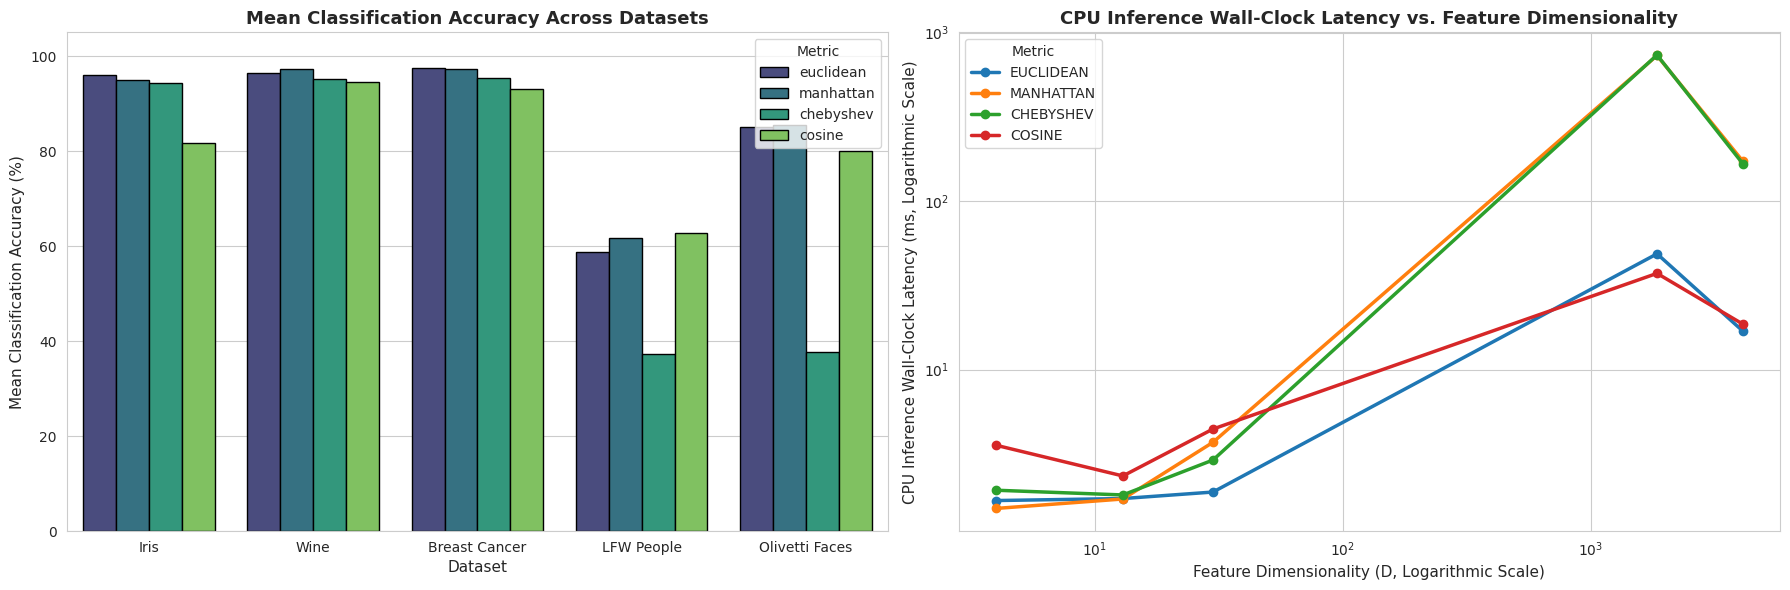

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (13 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Experimental protocol packaged successfully.


In [18]:
sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.barplot(
    data=df_master[df_master['Weights'] == 'uniform'],
    x='Dataset', y='Mean Accuracy (%)', hue='Metric',
    ax=axes[0], palette='viridis', edgecolor='black'
)
axes[0].set_title('Mean Classification Accuracy Across Datasets', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Dataset', fontsize=11)
axes[0].set_ylabel('Mean Classification Accuracy (%)', fontsize=11)
axes[0].set_ylim(0, 105)

dataset_to_features = {
    'Iris': 4,
    'Wine': 13,
    'Breast Cancer': 30,
    'LFW People': 1850,
    'Olivetti Faces': 4096
}

for metric in metrics:
    metric_subset = df_latency[(df_latency['Weights'] == 'uniform') & (df_latency['Metric'] == metric)].copy()
    metric_subset['Features'] = metric_subset['Dataset'].map(dataset_to_features)
    metric_subset = metric_subset.sort_values(by='Features')
    axes[1].plot(metric_subset['Features'], metric_subset['Mean Latency (ms)'], marker='o', linewidth=2.5, label=metric.upper())

axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_title('CPU Inference Wall-Clock Latency vs. Feature Dimensionality', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Feature Dimensionality (D, Logarithmic Scale)', fontsize=11)
axes[1].set_ylabel('CPU Inference Wall-Clock Latency (ms, Logarithmic Scale)', fontsize=11)
axes[1].legend(title='Metric')

plt.tight_layout()
graph_filename = 'dimensional_stress_benchmarks.png'
plt.savefig(graph_filename, dpi=300, bbox_inches='tight')
plt.show()

csv_filename = 'high_dim_computational_benchmarks.csv'
df_master.to_csv(csv_filename, index=False)

files.download(csv_filename)
files.download(graph_filename)
files.download('preprocessing_sensitivity_results.csv')
files.download('lfw_perclass_f1_results.csv')
files.download('pca_remedy_results.csv')
files.download('latency_remeasured_results.csv')
files.download('latency_remeasured_per_seed.csv')
files.download('latency_uncertainty_comparison.csv')
files.download('blas_thread_sweep_results.csv')
files.download('blas_control_condition_results.csv')
files.download('k_sensitivity_diagnostic.csv')
print("Experimental protocol packaged successfully.")